In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'data' / '3_train.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'data' / '3_val.parquet')
train_kf_oof = pd.read_parquet(PROJECT_ROOT / 'data' / '0_kf_oof.parquet')

In [2]:
# ============================================================
# 1. 최종 컬럼군 정의
# ============================================================

# 종속변수군
target_col = 'target_maxrise_6h'

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 독립변수군
feature_cols = [
    col for col in train.columns
    if col not in rain_int_cols + ['timestamp', 'event_id', target_col]
]

assert len(feature_cols) == 28, (
    f'독립변수 개수 이상: 예상 28개, 현재 {len(feature_cols)}개'
)

In [3]:
# ============================================================
# 2. OOF 잔차 생성
# ============================================================

train_kf_oof['resid'] = train_kf_oof['y_train'] - train_kf_oof['y_pred']
train_kf_oof['resid_sq'] = train_kf_oof['resid'] ** 2
train_kf_oof['resid_abs'] = train_kf_oof['resid'].abs()

train_kf_oof.head()

,event_id,y_train,y_pred,fold,resid,resid_sq,resid_abs
row_id,,,,,,,
TR_000222241,1,0.00,0.028109,5,-0.028109,0.000790,0.028109
TR_000288748,1,0.00,0.003864,5,-0.003864,0.000015,0.003864
TR_000737576,1,0.00,0.014299,5,-0.014299,0.000204,0.014299
TR_000651952,1,0.00,-0.008879,5,0.008879,0.000079,0.008879
TR_000328380,1,0.03,0.055385,5,-0.025385,0.000644,0.025385


In [ ]:
# ============================================================
# 2. 종속변수 구간별 RMSE: OOF 전체
# ============================================================

import numpy as np

# 종속변수 분위수 기준으로 구간 설정
q = [0, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]
labels = ['0~50%', '50~75%', '75~90%', '90~95%', '95~99%', '99~100%']

train_kf_oof['y_train_quant'] = pd.qcut(  # q분위수 기준으로 구간 나누기, 구간별 라벨 붙이는 함수
    train_kf_oof['y_train'],  # 매개변수: 구간을 나눌 기준 데이터
    q=q,  # 구간을 나눌 위치(분위수)
    labels=labels # 구간별 값 지정(q보다 하나 적어야 함)
)

# 구간별 RMSE 계산
rmse_y_train_segment = (
    train_kf_oof
    .groupby('y_train_quant', observed=True)  # observed=True: 관측된 행만 기재(count가 0인 행은 제거)
    .agg(
        count=('resid_sq', 'count'),
        mse=('resid_sq', 'mean'),  # 잔차제곱의 평균 = mse, 루트하면 rmse
        sse=('resid_sq', 'sum')
    )
)

rmse_y_train_segment['rmse'] = np.sqrt(rmse_y_train_segment['mse'])
rmse_y_train_segment['sse_pct(%)'] = (
    rmse_y_train_segment['sse']/
    rmse_y_train_segment['sse'].sum()
    *100
)

display(rmse_y_train_segment[['count', 'rmse', 'sse','sse_pct(%)']])

,count,rmse,sse,sse_pct(%)
y_train_quant,,,,
0~50%,340940,0.096909,3201.857307,9.648810
50~75%,127705,0.094898,1150.057611,3.465703
75~90%,87488,0.158383,2194.650339,6.613588
90~95%,29345,0.281637,2327.620578,7.014294
95~99%,24674,0.651542,10474.274399,31.564269
99~100%,6141,1.500990,13835.499620,41.693335


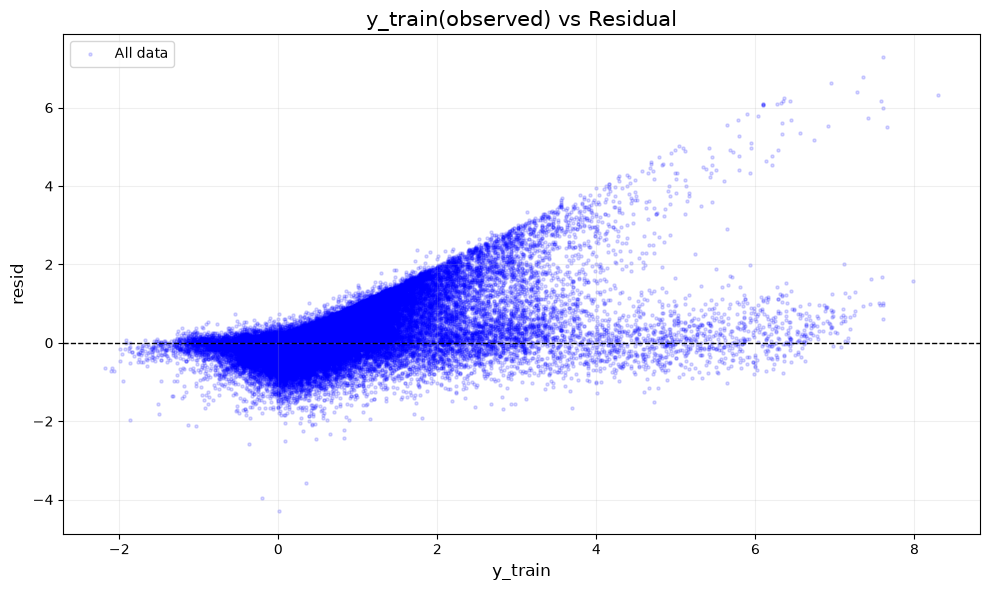

전체 데이터: 616,293


In [ ]:
# ============================================================
# 2-1. 실제값 - 예측잔차 산점도
# ============================================================

# 1. 분석 설정
df = train_kf_oof          # 분석 데이터(전체)
x_col = 'y_train'         # X축: 실제값
y_col = 'resid'         # Y축: 예측잔차
plot_title = 'y_train(observed) vs Residual'

# # 2. 강조 조건 설정 (True = 전체 데이터)
# cond = (
#     (df['station_id'] == 101)
#     # & (df['hour'] >= 12)
#     # & (df['hour'] < 18)
# )

# # 3. 조건별 데이터 구분
# highlight = df.loc[cond]   # 빨간색 강조 데이터

# 4. 산점도
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

# 전체 데이터: 회색
ax.scatter(
    df[x_col], df[y_col],
    color='blue', alpha=0.15, s=5,
    label='All data'
)

# # 조건 데이터: 빨간색
# ax.scatter(
#     highlight[x_col], highlight[y_col],
#     color='red', alpha=0.7, s=10,
#     label=f'Highlighted (n={len(highlight):,})'
# )

# 5. 그래프 설정
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title(plot_title, fontsize=15)
ax.set_xlabel(x_col, fontsize=12)
ax.set_ylabel(y_col, fontsize=12)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# 6. 강조 데이터 확인
print(f"전체 데이터: {len(df):,}")
# print(f"강조 데이터: {len(highlight):,}")
# print(f"강조 비율: {len(highlight)/len(df):.2%}")

In [ ]:
# ============================================================
# 3-1. 관측소별 RMSE: OOF 전체: 'station_id' 컬럼 추가
# ============================================================

assert train_kf_oof.index.equals(train.index), "train_kf_oof 인덱스 이상"
train_kf_oof['station_id'] = train['station_id']

train_kf_oof.head()

,event_id,y_train,y_pred,fold,resid,resid_sq,resid_abs,y_train_quant,station_id
row_id,,,,,,,,,
TR_000222241,1,0.00,0.028109,5,-0.028109,0.000790,0.028109,0~50%,ST0001
TR_000288748,1,0.00,0.003864,5,-0.003864,0.000015,0.003864,0~50%,ST0002
TR_000737576,1,0.00,0.014299,5,-0.014299,0.000204,0.014299,0~50%,ST0003
TR_000651952,1,0.00,-0.008879,5,0.008879,0.000079,0.008879,0~50%,ST0004
TR_000328380,1,0.03,0.055385,5,-0.025385,0.000644,0.025385,50~75%,ST0005


In [12]:
# ============================================================
# 2-1. 관측소별 RMSE: OOF 전체
# ============================================================

# 관측소별 RMSE 계산
station_rmse = (
    train_kf_oof
    .groupby('station_id', observed=True)  # observed=True: 관측된 행만 기재(count가 0인 행은 제거)
    .agg(
        count=('resid_sq', 'count'),
        sse=('resid_sq', 'sum'),
        mse=('resid_sq', 'mean')
    )
)

station_rmse['rmse'] = np.sqrt(station_rmse['mse'])
station_rmse['sse_contribution_pct(%)'] = (
    station_rmse['sse']/
    station_rmse['sse'].sum()
    *100
)
display(station_rmse.sort_values('sse_contribution_pct(%)', ascending=False))

,count,sse,mse,rmse,sse_contribution_pct(%)
station_id,,,,,
ST0445,991,410.598407,0.414327,0.643683,1.229034
ST0028,1379,402.844031,0.292128,0.540488,1.205823
ST0159,1379,394.241234,0.285889,0.534686,1.180072
ST0428,1379,363.247776,0.263414,0.513239,1.087300
ST0313,1379,353.623152,0.256434,0.506394,1.058491
...,...,...,...,...,...
ST0277,1379,6.087628,0.004415,0.066442,0.018222
ST0333,991,4.905819,0.004950,0.070359,0.014684
ST0442,1003,4.358581,0.004346,0.065921,0.013046


In [13]:
# ============================================================
# 2-2. 관측소별 RMSE: OOF 전체, 종속변수 상위 5%
# ============================================================

# 종속변수 상위 5% 데이터 추출: 앞에 정의됨
# high_y_resid = train_kf_oof.loc[
#     train_kf_oof['y_kf_val_quant'].isin(['95~99%', '99~100%'])
# ].copy()

# high_y_resid.head()

# 관측소별 RMSE 계산
high_station_rmse = (
    high_y_resid
    .groupby('station_id', observed=True)  # observed=True: 관측된 행만 기재(count가 0인 행은 제거)
    .agg(
        count=('resid_sq', 'count'),
        sse=('resid_sq', 'sum'),
        mse=('resid_sq', 'mean')
    )
)

high_station_rmse ['rmse'] = np.sqrt(high_station_rmse ['mse'])
high_station_rmse ['sse_contribution_pct(%)'] = (
    high_station_rmse ['sse']/
    high_station_rmse ['sse'].sum()
    *100
)
display(high_station_rmse.sort_values('sse_contribution_pct(%)', ascending=False))

,count,sse,mse,rmse,sse_contribution_pct(%)
station_id,,,,,
ST0445,67,378.922660,5.655562,2.378143,1.540592
ST0159,780,349.063267,0.447517,0.668967,1.419192
ST0028,166,333.606880,2.009680,1.417632,1.356351
ST0428,128,314.822464,2.459550,1.568295,1.279978
ST0448,82,290.624316,3.544199,1.882604,1.181596
...,...,...,...,...,...
ST0094,4,0.618475,0.154619,0.393216,0.002515
ST0032,3,0.566894,0.188965,0.434701,0.002305
ST0021,4,0.466655,0.116664,0.341561,0.001897


In [53]:
# ============================================================
# 3-1. 계측오류 의심구간 RMSE
# ============================================================

# 계측오류 의심 조건(train_correlation_analysis 참고)
cond_meas_error = train_kf_oof['wl_diff_6h'] < -2

# 구간별 RMSE 및 SSE
meas_error_analysis = (
    train_kf_oof
    .assign(
        error_group=np.where(cond_meas_error, '계측오류 의심', '나머지 구간')
    )
    .groupby('error_group')
    .agg(
        count=('resid_sq', 'count'),
        sse=('resid_sq', 'sum'),
        mse=('resid_sq', 'mean')
    )
)

meas_error_analysis['rmse'] = np.sqrt(meas_error_analysis['mse'])

# 전체 SSE 대비 기여율
meas_error_analysis['sse_contribution_pct(%)'] = (
    meas_error_analysis['sse'] / meas_error_analysis['sse'].sum() * 100
)

display(meas_error_analysis)

# 전체 OOF RMSE
print(
    '전체 OOF RMSE:',
    np.sqrt(train_kf_oof['resid_sq'].mean())
)

,count,sse,mse,rmse,sse_contribution_pct(%)
error_group,,,,,
계측오류 의심,2332,756.147667,0.324249,0.569428,2.263357
나머지 구간,613961,32652.082390,0.053183,0.230614,97.736643


전체 OOF RMSE: 0.2328268788913155


,threshold,count,count_pct(%),sse,sse_contribution_pct(%),rmse,error_concentration
0,-0.1,49441,8.022321,5549.518488,16.611232,0.335030,2.070627
1,-0.5,12244,1.986717,2500.299289,7.484082,0.451892,3.767059
2,-1.0,5323,0.863713,1507.575420,4.512587,0.532183,5.224640
3,-1.5,3338,0.541625,1060.130641,3.173262,0.563555,5.858775
4,-2.0,2332,0.378391,756.147667,2.263357,0.569428,5.981524
5,-2.5,1652,0.268054,541.525253,1.620934,0.572538,6.047034
6,-3.0,1208,0.196011,395.894726,1.185022,0.572475,6.045699
7,-3.5,937,0.152038,327.301596,0.979703,0.591023,6.443804
8,-4.0,722,0.117152,257.731826,0.771462,0.597469,6.585134
9,-4.5,549,0.089081,203.359339,0.608710,0.608620,6.833222


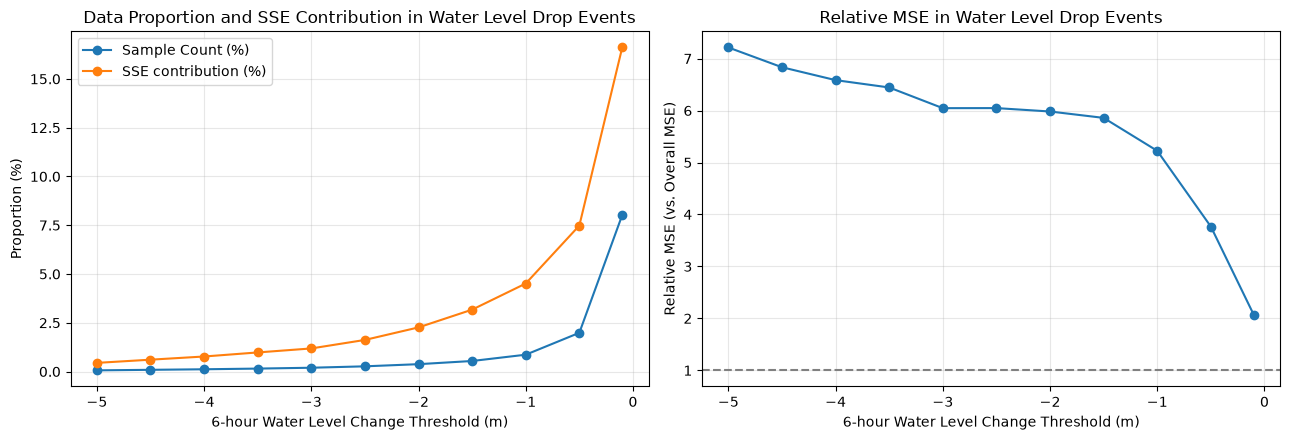

In [7]:
# ============================================================
# 3-2. 계측오류 의심 임계값별 RMSE 및 SSE 기여율 비교
# ============================================================

import numpy as np

thresholds = [-0.1, -0.5, -1, -1.5, -2, -2.5, -3, -3.5, -4, -4.5, -5]

total_count = train_kf_oof['resid_sq'].count()
total_sse = train_kf_oof['resid_sq'].sum()

meas_error_results = []

for threshold in thresholds:

    cond_meas_error = train_kf_oof['wl_diff_6h'] < threshold
    error_data = train_kf_oof.loc[cond_meas_error, 'resid_sq']

    count = error_data.count()
    sse = error_data.sum()
    mse = error_data.mean()

    meas_error_results.append({
        'threshold': threshold,
        'count': count,
        'count_pct(%)': count / total_count * 100,
        'sse': sse,
        'sse_contribution_pct(%)': sse / total_sse * 100,
        'rmse': np.sqrt(mse),
        'error_concentration': (
            (sse / total_sse) / (count / total_count)
            if count > 0 else np.nan
        )
    })

meas_error_threshold = pd.DataFrame(meas_error_results)

display(meas_error_threshold)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. 임계값에 따른 count 비율과 SSE 기여율
axes[0].plot(
    meas_error_threshold['threshold'],
    meas_error_threshold['count_pct(%)'],
    marker='o', label='Sample Count (%)'
)

axes[0].plot(
    meas_error_threshold['threshold'],
    meas_error_threshold['sse_contribution_pct(%)'],
    marker='o', label='SSE contribution (%)'
)

axes[0].set_xlabel('6-hour Water Level Change Threshold (m)')
axes[0].set_ylabel('Proportion (%)')
axes[0].set_title('Data Proportion and SSE Contribution in Water Level Drop Events')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. 임계값에 따른 오차 집중 배율
axes[1].plot(
    meas_error_threshold['threshold'],
    meas_error_threshold['error_concentration'],
    marker='o'
)

axes[1].axhline(1, linestyle='--', color='gray')
axes[1].set_xlabel('6-hour Water Level Change Threshold (m)')
axes[1].set_ylabel('Relative MSE (vs. Overall MSE)')
axes[1].set_title('Relative MSE in Water Level Drop Events')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 4-1. 사상(event_id)별 전체 SSE 및 RMSE 분석
# ============================================================
# 분석 목적
# - 전체 예측오차가 특정 수위변동 사상에 집중되는지 확인
# - 사상별 SSE 기여율을 통해 전체 RMSE에 미치는 영향 파악
# - 사상별 RMSE를 통해 관측치 수에 따른 영향을 구분
#
# 분석 방법
# - event_id별 관측치 수, 관측소 수, SSE, RMSE 계산
# - 전체 SSE 대비 사상별 기여율 및 누적 기여율 산출
# - SSE가 큰 사상부터 정렬하여 상위 20개 확인
# ============================================================

# 1. 전체 SSE 계산
total_sse = train_kf_oof['resid_sq'].sum()

# 2. event_id별 오차 집계
event_error = (
    train_kf_oof
    .groupby('event_id')
    .agg(
        count=('resid_sq', 'size'),
        station_count=('station_id', 'nunique'),
        sse=('resid_sq', 'sum'),
        mse=('resid_sq', 'mean')
    )
)

# 3. RMSE 및 SSE 기여율 계산
event_error['rmse'] = np.sqrt(event_error['mse'])

event_error['sse_pct'] = (
    event_error['sse'] / total_sse * 100
)

# 4. SSE 내림차순 정렬 및 누적 기여율 계산
event_error = event_error.sort_values('sse', ascending=False)

event_error['cumulative_sse_pct'] = (
    event_error['sse_pct'].cumsum()
)

# 5. SSE 상위 20개 사상 확인
display(event_error.head(20))

,count,station_count,sse,mse,rmse,sse_pct,cumulative_sse_pct
event_id,,,,,,,
98,71567,464,7696.683084,0.107545,0.327941,23.038284,23.038284
90,24970,465,3795.923741,0.152019,0.389897,11.362241,34.400526
35,19967,465,3318.868811,0.166218,0.407698,9.934285,44.334811
97,7408,463,3212.073848,0.433595,0.658480,9.614618,53.949429
3,18059,464,2627.781318,0.145511,0.381459,7.865671,61.815100
89,25289,464,2286.620361,0.090420,0.300698,6.844482,68.659582
28,28931,465,939.044562,0.032458,0.180161,2.810818,71.470400
96,19530,465,810.445352,0.041497,0.203709,2.425885,73.896286
7,18192,465,786.295414,0.043222,0.207899,2.353598,76.249883


In [ ]:
# ============================================================
# 4-2. 잔차제곱 상위 1% 데이터의 사상(event_id)별 집중도 분석
# ============================================================
# 분석 목적
# - 극단적인 예측오차가 특정 사상에서 반복적으로 발생하는지 확인
# - 고잔차가 동일 사상의 여러 관측소에서 발생하는지 확인
# - 상위 고잔차 사상이 전체 SSE에 미치는 영향 파악
#
# 분석 방법
# - 전체 OOF 데이터에서 잔차제곱 상위 1% 추출
# - event_id별 고잔차 발생 횟수, 관측소 수, SSE 계산
# - 전체 SSE 대비 기여율 및 누적 기여율 산출
# - 고잔차 SSE가 큰 사상부터 상위 20개 확인
# ============================================================

# 1. 잔차제곱 상위 1% 기준값 계산
threshold = train_kf_oof['resid_sq'].quantile(0.99)

# 2. 잔차제곱 상위 1% 데이터 추출
high_error = train_kf_oof.loc[
    train_kf_oof['resid_sq'] >= threshold
].copy()

# 3. event_id별 고잔차 집계
high_error_event = (
    high_error
    .groupby('event_id')
    .agg(
        high_error_count=('resid_sq', 'size'),
        station_count=('station_id', 'nunique'),
        high_error_sse=('resid_sq', 'sum')
    )
)

# 4. 전체 SSE 대비 고잔차 기여율 계산
high_error_event['total_sse_pct'] = (
    high_error_event['high_error_sse'] / total_sse * 100
)

# 5. 고잔차 SSE 내림차순 정렬 및 누적 기여율 계산
high_error_event = (
    high_error_event
    .sort_values('high_error_sse', ascending=False)
)

high_error_event['cumulative_sse_pct'] = (
    high_error_event['total_sse_pct'].cumsum()
)

# 6. 고잔차 SSE 상위 20개 사상 확인
display(high_error_event.head(20))

,high_error_count,station_count,high_error_sse,total_sse_pct,cumulative_sse_pct
event_id,,,,,
98,1680,274,4384.874835,13.125134,13.125134
90,555,133,3041.101441,9.102851,22.227985
97,791,195,2563.307737,7.672683,29.900668
35,763,160,2429.560253,7.272341,37.173009
3,567,134,1771.450202,5.302437,42.475445
89,353,79,1537.437550,4.601972,47.077418
67,154,60,446.279567,1.335837,48.413255
28,165,51,383.057952,1.146598,49.559852
29,107,33,317.570931,0.950577,50.510429
